# Pipeline dữ liệu ALL cho bốn mô hình
Chạy lần lượt trên Colab để chuẩn bị dữ liệu cho CNN tự xây, ResNet50, MobileNetV2 và EfficientNet-B0. Original và Segmented dùng chung split theo nhóm ảnh, mỗi luồng có loader train, validation và test riêng.

**Geometry cho train:** xoay ±20°, dịch tối đa 10% mỗi chiều, scale 0.9–1.1, lật ngang và dọc độc lập với xác suất 0.5. Validation và test chỉ chuyển RGB, tạo tensor và normalize. Cả bốn mô hình dùng ảnh RGB 224×224.

Notebook giữ đường dẫn Google Drive và split của thí nghiệm đã chốt. Chạy bằng CPU được. Các cell xuất `all_data_pipeline.py`, cấu hình, manifest và trọng số lớp để dùng trong notebook huấn luyện.


## 1. Thư viện và cấu hình
Có thể chạy bằng CPU. Nếu vừa đổi runtime Colab, chạy lại từ đầu để khôi phục biến và hàm.

In [ ]:
# Bỏ dấu # nếu môi trường chưa có thư viện, sau đó khởi động lại kernel.
%pip install torch torchvision pandas numpy pillow scikit-learn matplotlib imagehash

In [ ]:
from pathlib import Path
import json, random, hashlib, platform, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import imagehash
import torch
import torchvision
from torchvision.models import MobileNet_V2_Weights, ResNet50_Weights, EfficientNet_B0_Weights
from sklearn.model_selection import GroupShuffleSplit
from IPython.display import display

USE_COLAB = True
ZIP_PATH = Path('/content/drive/MyDrive/ALL_project/data-ALL.zip')
EXTRACT_DIR = Path('/content/ALL_data')
DATA_ROOT = Path('/content/ALL_data/data-ALL')
OUTPUT_DIR = Path('/content/drive/MyDrive/ALL_project/ALL_preprocessing_separate')
# Giữ thư mục có split đã dùng trong notebook so sánh.
PIPELINE_DIR = OUTPUT_DIR / 'auto_group_phash4_v1'

SEED = 42
CLASSES = ['Benign', 'Early', 'Pre', 'Pro']
CLASS_TO_IDX = {name: i for i, name in enumerate(CLASSES)}
VIEWS = ['original', 'segmented']
INPUT_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 0
TRAIN_RATIO, VAL_RATIO, TEST_RATIO = 0.70, 0.15, 0.15
PHASH_DISTANCE = 4

WEIGHTS = {
    'resnet50': ResNet50_Weights.IMAGENET1K_V2,
    'mobilenet_v2': MobileNet_V2_Weights.IMAGENET1K_V2,
    'efficientnet_b0': EfficientNet_B0_Weights.IMAGENET1K_V1,
}
# CNN tự xây dùng cùng chuẩn hóa ImageNet để giữ đầu vào nhất quán.
CNN_MEAN = (0.485, 0.456, 0.406)
CNN_STD = (0.229, 0.224, 0.225)
GEOMETRY = dict(rotation=20, translate=0.10, scale=(0.9, 1.1), flip_p=0.5)
SELECTED_CONFIG = {view: '02_geometry' for view in VIEWS}

def reset_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

reset_seed()
print('Python:', platform.python_version(), '| torch:', torch.__version__, '| torchvision:', torchvision.__version__)
display(pd.DataFrame([GEOMETRY], index=['Geometry']))
REFERENCE_SPLIT_FINGERPRINT = '771c797e0be7ad26144f24249802bccefbf3bd4a7363d8d86084e9f77163edcf'

REFERENCE_NOTEBOOK_SHA256 = 'b8d421371ba9543b5c6591530ce4a77d833dc5a0ff3d9dc41c830a4b7318add9'


Python: 3.13.18 | torch: 2.14.1+cpu | torchvision: 0.29.1+cpu


,rotation,translate,scale,flip_p
Geometry,20,0.1,"(0.9, 1.1)",0.5


## 2. Kết nối, kiểm tra ảnh và ghép cặp
Không resize/crop; ảnh khác 224×224, ảnh lỗi hoặc thiếu cặp sẽ được báo cáo và dừng. Không sửa ảnh nguồn.

In [ ]:
if USE_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

if not all((DATA_ROOT / view).is_dir() for view in ['Original', 'Segmented']):
    if not ZIP_PATH.is_file():
        raise FileNotFoundError(f'Không tìm thấy dữ liệu hoặc ZIP: {ZIP_PATH}')
    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH) as archive:
        archive.extractall(EXTRACT_DIR)
PIPELINE_DIR.mkdir(parents=True, exist_ok=True)
print('Dữ liệu:', DATA_ROOT)
print('Kết quả:', PIPELINE_DIR)

Mounted at /content/drive
Dữ liệu: /content/ALL_data/data-ALL
Kết quả: /content/drive/MyDrive/ALL_project/ALL_preprocessing_separate/auto_group_phash4_v1


In [ ]:
def scan_dataset(root):
    records, errors = [], []
    extensions = {'.jpg','.jpeg','.png','.bmp','.tif','.tiff'}
    for view in ['Original','Segmented']:
        for cls in CLASSES:
            folder = root/view/cls
            if not folder.is_dir():
                errors.append(dict(path=str(folder),error='Thiếu thư mục')); continue
            for path in sorted(folder.iterdir()):
                if path.suffix.lower() not in extensions: continue
                try:
                    with Image.open(path) as im:
                        im.load()
                        rgb = im.convert('RGB'); arr = np.asarray(rgb)
                        if rgb.size != (INPUT_SIZE, INPUT_SIZE):
                            raise ValueError(f'Ảnh phải là {INPUT_SIZE}×{INPUT_SIZE}, nhận {rgb.size}; không tự resize/crop')
                        ph = str(imagehash.phash(rgb))
                    digest = hashlib.sha256(str(arr.shape).encode()+arr.tobytes()).hexdigest()
                    records.append(dict(sample_id=f'{cls}/{path.stem}', label=cls,
                        target=CLASS_TO_IDX[cls], view=view.lower(), relative_path=path.relative_to(root).as_posix(),
                        width=arr.shape[1],height=arr.shape[0],pixel_hash=digest,phash=ph))
                except Exception as exc:
                    errors.append(dict(path=str(path),error=str(exc)))
            print(f'Đã kiểm tra: {view}/{cls}', flush=True)
    return pd.DataFrame(records), pd.DataFrame(errors,columns=['path','error'])

manifest, errors = scan_dataset(DATA_ROOT)
errors.to_csv(PIPELINE_DIR/'read_errors.csv',index=False)
manifest.to_csv(PIPELINE_DIR/'image_manifest.csv',index=False)
if manifest.empty: raise RuntimeError('Không tìm thấy ảnh đọc được.')
display(pd.crosstab(manifest['label'],manifest['view']).reindex(CLASSES))
display(manifest.groupby(['view','width','height']).size().rename('count'))
if manifest.duplicated(['sample_id','view']).any():
    raise ValueError('Có nhiều tệp cùng stem/nhãn/view; sửa tên trước khi ghép.')
pair_counts = manifest.groupby('sample_id')['view'].nunique()
missing = manifest[manifest.sample_id.isin(pair_counts[pair_counts!=2].index)]
missing.to_csv(PIPELINE_DIR/'missing_pairs.csv',index=False)
if len(errors) or len(missing):
    raise RuntimeError('Có ảnh lỗi/thiếu cặp. Xem read_errors.csv và missing_pairs.csv rồi chạy lại.')
pairs = manifest.pivot(index=['sample_id','label','target'],columns='view',values='relative_path').reset_index()
pairs.columns.name = None
assert set(pairs.label)==set(CLASSES), 'Dữ liệu phải đủ bốn lớp'

Đã kiểm tra: Original/Benign
Đã kiểm tra: Original/Early
Đã kiểm tra: Original/Pre
Đã kiểm tra: Original/Pro
Đã kiểm tra: Segmented/Benign
Đã kiểm tra: Segmented/Early
Đã kiểm tra: Segmented/Pre
Đã kiểm tra: Segmented/Pro


view,original,segmented
label,,
Benign,504,504
Early,985,985
Pre,963,963
Pro,804,804


,,,count
view,width,height,
original,224,224,3256
segmented,224,224,3256


## 3. Tự động gom nhóm SHA-256 và pHash ≤4
SHA-256 tính trên pixel RGB của cả hai view. Ảnh trùng pixel nhưng nhãn khác nhau sẽ báo lỗi. pHash quét mọi cặp Original và tự union nếu khoảng cách ≤4, kể cả cặp khác nhãn; các cặp khác nhãn được xuất riêng để biết, không tự đổi nhãn. Nhóm có thể chứa nhiều nhãn; splitter vẫn giữ cả nhóm cùng tập.

Số dòng báo cáo pHash là số cặp; số dòng báo cáo SHA là số bản ghi ảnh thuộc nhóm trùng, không phải số cặp. Nếu nhóm quá lớn khiến không chia đủ bốn lớp, notebook dừng; không chia nhỏ nhóm để ép tỷ lệ.

In [ ]:
parent = {sid: sid for sid in pairs['sample_id']}

def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

def union(a, b):
    a, b = find(a), find(b)
    if a != b:
        parent[max(a, b)] = min(a, b)

exact = manifest[manifest.duplicated('pixel_hash', keep=False)].copy()
exact.to_csv(PIPELINE_DIR/'exact_duplicates.csv', index=False)
for _, block in exact.groupby('pixel_hash'):
    if block['label'].nunique() > 1:
        raise ValueError('Ảnh trùng pixel có nhãn khác nhau: xem exact_duplicates.csv')
    ids = block['sample_id'].unique().tolist()
    for sid in ids[1:]:
        union(ids[0], sid)

orig = manifest[manifest['view']=='original'].reset_index(drop=True)
hashes = [int(value, 16) for value in orig['phash']]
ids = orig['sample_id'].tolist()
near = []
for i in range(len(orig)):
    for j in range(i+1, len(orig)):
        distance = (hashes[i] ^ hashes[j]).bit_count()
        if distance <= PHASH_DISTANCE:
            near.append((ids[i], ids[j], distance))
            union(ids[i], ids[j])

near_df = pd.DataFrame(near, columns=['sample_id_a', 'sample_id_b', 'phash_distance'])
near_df.to_csv(PIPELINE_DIR/'near_duplicates_grouped.csv', index=False)
labels = pairs.set_index('sample_id')['label']
cross_label = near_df[near_df.sample_id_a.map(labels) != near_df.sample_id_b.map(labels)]
cross_label.to_csv(PIPELINE_DIR/'near_duplicates_cross_label.csv', index=False)

pairs['group_id'] = pairs['sample_id'].map(find)
groups = pairs.set_index('sample_id')['group_id']
assert (near_df.sample_id_a.map(groups) == near_df.sample_id_b.map(groups)).all()
pairs[['sample_id', 'label', 'group_id']].to_csv(PIPELINE_DIR/'sample_groups.csv', index=False)
group_sizes = pairs.groupby('group_id').size()
print('Bản ghi ảnh thuộc nhóm SHA trùng:', len(exact))
print('Cặp pHash đã gom:', len(near_df), '| Cặp khác nhãn:', len(cross_label))
print('Ảnh nguồn:', len(pairs), '| Nhóm:', len(group_sizes), '| Nhóm lớn nhất:', group_sizes.max())

Bản ghi ảnh thuộc nhóm SHA trùng: 160
Cặp pHash đã gom: 95 | Cặp khác nhãn: 0
Ảnh nguồn: 3256 | Nhóm: 3163 | Nhóm lớn nhất: 3


## 4. Chia nhóm và kiểm tra chống rò rỉ
Dùng GroupShuffleSplit, chọn trong 250 ứng viên dựa trên tỷ lệ và phân bố lớp, mục tiêu 70/15/15. Không dùng kết quả mô hình để chia. Split lưu cố định; nếu thay dữ liệu/nhóm/cấu hình chia phải dùng thư mục con mới.

Các kiểm tra bảo đảm group, Original–Segmented cùng ảnh, hash pixel giống nhau và mọi cặp pHash đã gắn cờ đều chỉ ở một tập. Không bảo đảm phát hiện mọi quan hệ cùng bệnh nhân/tiêu bản hoặc mọi biến thể ảnh.

In [ ]:
def best_group_holdout(frame, fraction, seed):
    splitter=GroupShuffleSplit(n_splits=250,test_size=fraction,random_state=seed)
    target=frame.target.value_counts(normalize=True).reindex(range(4),fill_value=0)
    best=None
    for keep,take in splitter.split(frame,frame.target,frame.group_id):
        a,b=frame.iloc[keep],frame.iloc[take]
        if a.target.nunique()!=4 or b.target.nunique()!=4: continue
        dist=b.target.value_counts(normalize=True).reindex(range(4),fill_value=0)
        score=abs(len(b)/len(frame)-fraction)+float(abs(dist-target).sum())
        if best is None or score<best[0]: best=(score,keep,take)
    if best is None: raise ValueError('Không tìm được cách chia nhóm đủ 4 lớp; kiểm tra metadata/số nhóm.')
    return best[1],best[2]

pairs['content_fingerprint'] = pairs.sample_id.map(manifest.sort_values('view').groupby('sample_id')['pixel_hash'].agg('|'.join))
split_file=PIPELINE_DIR/'split_pairs.csv'
split_settings = dict(seed=SEED, ratios=[TRAIN_RATIO, VAL_RATIO, TEST_RATIO], phash_distance=PHASH_DISTANCE, grouping='sha_rgb_and_original_phash_connected_components')
split_settings_file = PIPELINE_DIR/'split_settings.json'
if split_file.exists():
    if not split_settings_file.exists() or json.loads(split_settings_file.read_text()) != split_settings:
        raise RuntimeError('Thiết lập split khác hoặc thiếu: dùng PIPELINE_DIR mới.')
identity_cols=['sample_id','label','original','segmented','group_id','content_fingerprint']
if split_file.exists():
    saved=pd.read_csv(split_file,keep_default_na=False)
    left=pairs[identity_cols].sort_values('sample_id').reset_index(drop=True)
    right=saved[identity_cols].sort_values('sample_id').reset_index(drop=True)
    if not left.equals(right): raise RuntimeError('Dữ liệu/metadata khác split cũ. Dùng PIPELINE_DIR mới.')
    pairs=pairs.merge(saved[['sample_id','split']],on='sample_id',validate='one_to_one')
else:
    keep,test=best_group_holdout(pairs,TEST_RATIO,SEED)
    remaining=pairs.iloc[keep]
    tr,va=best_group_holdout(remaining,VAL_RATIO/(TRAIN_RATIO+VAL_RATIO),SEED+1)
    pairs['split']='test'
    pairs.loc[remaining.iloc[tr].index,'split']='train'
    pairs.loc[remaining.iloc[va].index,'split']='val'
    pairs.to_csv(split_file,index=False)
assert pairs.groupby('group_id').split.nunique().max()==1
assert pairs.groupby('sample_id').split.nunique().max()==1
assert set(pairs.split)=={'train','val','test'}
assert (pairs.groupby('split').target.nunique()==4).all()
display(pd.crosstab(pairs.label,pairs.split).reindex(CLASSES))
print(pairs.split.value_counts(normalize=True))
manifest=manifest.merge(pairs[['sample_id','group_id','split']],on='sample_id',validate='many_to_one')
manifest.to_csv(PIPELINE_DIR/'manifest_with_splits.csv',index=False)
lookup = pairs.set_index('sample_id')['split']
near_df['split_a'] = near_df.sample_id_a.map(lookup)
near_df['split_b'] = near_df.sample_id_b.map(lookup)
cross = near_df[near_df.split_a != near_df.split_b]
cross.to_csv(PIPELINE_DIR/'near_duplicates_cross_split.csv', index=False)
assert cross.empty, 'Còn cặp pHash nằm khác tập'
assert (manifest.groupby('pixel_hash')['split'].nunique() <= 1).all(), 'Còn ảnh trùng pixel nằm khác tập'

# Fingerprint gắn cấu hình pipeline với đúng dữ liệu và split.
def split_fingerprint(frame):
    cols = ['sample_id', 'label', 'original', 'segmented', 'group_id', 'content_fingerprint', 'split']
    payload = frame[cols].sort_values('sample_id').to_csv(index=False)
    return hashlib.sha256(payload.encode('utf-8')).hexdigest()

SPLIT_FINGERPRINT = split_fingerprint(pairs)
print('OK: 0 cặp SHA/pHash đã phát hiện nằm khác tập.')

split_settings_file.write_text(json.dumps(split_settings, indent=2), encoding='utf-8')
# Không gắn kết luận đã có sang một split mới/khác.
if SPLIT_FINGERPRINT != REFERENCE_SPLIT_FINGERPRINT:
    raise RuntimeError('Dữ liệu/split không khớp lần so sánh đã chạy. Giữ nguyên dữ liệu và split_pairs.csv gốc; không xóa guard này để ép dùng kết luận cũ.')
print('Fingerprint khớp chính xác với split đã dùng để so sánh.')

split,test,train,val
label,,,
Benign,75,353,76
Early,148,693,144
Pre,148,671,144
Pro,120,564,120


split
train    0.700553
test     0.150799
val      0.148649
Name: proportion, dtype: float64
OK: 0 cặp SHA/pHash đã phát hiện nằm khác tập.
Fingerprint khớp chính xác với split đã dùng để so sánh.


## 5. Lưu cấu hình Geometry
Train: RGB → affine với nội suy bilinear → lật ngang/dọc → tensor → normalize. Vùng trống của affine lấy màu trung vị viền trên Original và màu đen trên Segmented. Validation và test chỉ chuyển RGB, tạo tensor rồi normalize. Batch size mặc định 32, chỉ train được shuffle. Trọng số lớp được tính từ train.


In [ ]:
normalization = {}
for name, weights in WEIGHTS.items():
    preset = weights.transforms()  # chỉ lấy mean/std, không gọi resize/crop của preset
    normalization[name] = dict(mean=list(preset.mean), std=list(preset.std))
normalization['custom_cnn'] = dict(mean=list(CNN_MEAN), std=list(CNN_STD))

for split in ['train', 'val', 'test']:
    for view in VIEWS:
        manifest[(manifest['split']==split) & (manifest['view']==view)].to_csv(
            PIPELINE_DIR/f'{split}_{view}.csv', index=False)

main_settings = dict(
    schema_version=1, seed=SEED, data_root=str(DATA_ROOT),
    manifest_file='manifest_with_splits.csv', split_file='split_pairs.csv',
    split_fingerprint=SPLIT_FINGERPRINT, classes=CLASS_TO_IDX,
    selected_config=SELECTED_CONFIG, augmentation={view: GEOMETRY for view in VIEWS},
    normalization=normalization, input_size=[3, INPUT_SIZE, INPUT_SIZE],
    resize=False, center_crop=False,
    batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
    grouping=split_settings,
    pretrained_weights={name: str(w) for name, w in WEIGHTS.items()},
    versions=dict(python=platform.python_version(), torch=str(torch.__version__),
                  torchvision=str(torchvision.__version__)),
    selection=dict(method='selected_from_recorded_validation', configuration='Geometry',
                   compared=True, reference_model='mobilenet_v2', reference_seed=42,
                   comparison_epochs=10, comparison_patience=3,
                   comparison_split_fingerprint=REFERENCE_SPLIT_FINGERPRINT,
                   source_notebook='ALL_preprocess (3).ipynb',
                   source_sha256=REFERENCE_NOTEBOOK_SHA256,
                   note='Lowest validation loss and highest accuracy/macro-F1 in both views; one seed only'),
)
(PIPELINE_DIR/'main_pipeline_config.json').write_text(
    json.dumps(main_settings, ensure_ascii=False, indent=2), encoding='utf-8')
print('Đã chốt Geometry từ kết quả validation:', SELECTED_CONFIG)

Đã chốt Geometry từ kết quả validation: {'original': '02_geometry', 'segmented': '02_geometry'}


## 6. Xuất module và tạo pipeline cho 4 mô hình

Mỗi mô hình có 6 loader: train/val/test × Original/Segmented. Mỗi batch trả `(images, labels)`: images float32 `(B,3,224,224)`, labels int64 `(B,)` từ 0 đến 3. Mỗi loader chỉ chứa một view. Các model pretrained không được khởi tạo hoặc tải trọng số ở bước chuẩn bị dữ liệu.

Module `all_data_pipeline.py` đọc cấu hình/CSV để tạo loader trong notebook huấn luyện khác. Hàm `build_main_pipeline` trả `(loaders, class_weights)`; trọng số lớp là `N/(4*n_c)` chỉ từ train. Không oversampling. Test loader được tạo nhưng không được duyệt ở notebook này.

In [ ]:
PIPELINE_MODULE_SOURCE = r'''
"""Pipeline ALL chốt Geometry từ validation; không huấn luyện hoặc đánh giá mô hình."""
from pathlib import Path
import json, random, hashlib
import numpy as np
import pandas as pd
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from torchvision.transforms import functional as TF, InterpolationMode

class CellTransform:
    def __init__(self, stats, config, training, input_size):
        self.mean, self.std = stats['mean'], stats['std']
        self.cfg = config
        self.training = training
        self.size = input_size

    def __call__(self, image, view):
        image = image.convert('RGB')
        if image.size != (self.size, self.size):
            raise ValueError(f'Cần ảnh {self.size}×{self.size}, nhận {image.size}')
        if self.training:
            cfg = self.cfg
            if cfg['rotation'] or cfg['translate'] or tuple(cfg['scale']) != (1.0, 1.0):
                arr = np.asarray(image)
                border = np.concatenate([arr[0], arr[-1], arr[:, 0], arr[:, -1]])
                fill = (0, 0, 0) if view == 'segmented' else tuple(int(v) for v in np.median(border, axis=0))
                angle, translation, scale, shear = T.RandomAffine.get_params(
                    [-cfg['rotation'], cfg['rotation']], [cfg['translate']]*2,
                    list(cfg['scale']), None, list(image.size))
                image = TF.affine(image, angle, translation, scale, shear,
                                  interpolation=InterpolationMode.BILINEAR, fill=fill)
            if torch.rand(()).item() < cfg['flip_p']:
                image = TF.hflip(image)
            if torch.rand(()).item() < cfg['flip_p']:
                image = TF.vflip(image)
        return TF.normalize(TF.to_tensor(image), self.mean, self.std)

class ALLImageDataset(Dataset):
    def __init__(self, rows, transform, root):
        self.rows = rows.reset_index(drop=True).copy()
        self.transform = transform
        self.root = Path(root)
    def __len__(self):
        return len(self.rows)
    def __getitem__(self, index):
        row = self.rows.iloc[index]
        with Image.open(self.root / row.relative_path) as image:
            x = self.transform(image, row['view'])
        return x, int(row.target)

def seed_worker(worker_id):
    seed = torch.initial_seed() % (2**32)
    random.seed(seed)
    np.random.seed(seed)

def build_main_pipeline(model_name, pipeline_dir=None, data_root=None, batch_size=None, num_workers=None):
    folder = Path(pipeline_dir) if pipeline_dir is not None else Path(__file__).resolve().parent
    cfg = json.loads((folder/'main_pipeline_config.json').read_text(encoding='utf-8'))
    if model_name not in cfg['normalization']:
        raise ValueError(f'Mô hình không hợp lệ: {model_name}')
    if cfg['input_size'] != [3, 224, 224] or cfg['resize'] or cfg['center_crop']:
        raise ValueError('Thiết lập kích thước không được hỗ trợ bởi pipeline này')
    geometry_keys = {'rotation', 'translate', 'scale', 'flip_p'}
    for view in ('original', 'segmented'):
        if set(cfg['augmentation'][view]) != geometry_keys:
            raise ValueError('Cấu hình Geometry không hợp lệ. Chạy lại cell lưu cấu hình.')
    rows = pd.read_csv(folder/cfg['manifest_file'], keep_default_na=False)
    split = pd.read_csv(folder/cfg['split_file'], keep_default_na=False)
    cols = ['sample_id', 'label', 'original', 'segmented', 'group_id', 'content_fingerprint', 'split']
    fingerprint = hashlib.sha256(split[cols].sort_values('sample_id').to_csv(index=False).encode('utf-8')).hexdigest()
    if fingerprint != cfg['split_fingerprint']:
        raise RuntimeError('Split khác thời điểm chốt pipeline')
    expected = split[['sample_id', 'group_id', 'split', 'label', 'target']].sort_values('sample_id').reset_index(drop=True)
    for view in ['original', 'segmented']:
        actual = rows[rows['view']==view][expected.columns].sort_values('sample_id').reset_index(drop=True)
        if not actual.equals(expected):
            raise RuntimeError(f'Manifest/split không khớp: {view}')
        actual_paths = rows[rows['view']==view].set_index('sample_id')['relative_path'].sort_index()
        expected_paths = split.set_index('sample_id')[view].sort_index()
        if actual_paths.to_dict() != expected_paths.to_dict():
            raise RuntimeError(f'Đường dẫn manifest/split không khớp: {view}')
    if rows.duplicated(['sample_id','view']).any() or (rows.groupby('group_id')['split'].nunique()>1).any():
        raise RuntimeError('Manifest bị trùng khóa hoặc group nằm khác tập')
    root = Path(data_root) if data_root is not None else Path(cfg['data_root'])
    bs = cfg['batch_size'] if batch_size is None else batch_size
    nw = cfg['num_workers'] if num_workers is None else num_workers
    if bs < 1 or nw < 0:
        raise ValueError('batch_size phải >0; num_workers phải >=0')
    loaders, weights = {}, {}
    for view in ['original', 'segmented']:
        train_rows = rows[(rows['view']==view) & (rows['split']=='train')]
        counts = train_rows.target.value_counts().reindex(range(len(cfg['classes'])), fill_value=0)
        if (counts == 0).any():
            raise RuntimeError('Train thiếu lớp')
        weights[view] = torch.tensor(len(train_rows)/(len(cfg['classes'])*counts.to_numpy()), dtype=torch.float32)
        for split_name in ['train', 'val', 'test']:
            selected = rows[(rows['view']==view) & (rows['split']==split_name)]
            if selected.empty:
                raise RuntimeError(f'Tập rỗng: {split_name}/{view}')
            transform = CellTransform(cfg['normalization'][model_name], cfg['augmentation'][view],
                                      split_name=='train', cfg['input_size'][1])
            dataset = ALLImageDataset(selected, transform, root)
            loaders[f'{split_name}_{view}'] = DataLoader(
                dataset, batch_size=bs, shuffle=(split_name=='train'), num_workers=nw,
                pin_memory=torch.cuda.is_available(), worker_init_fn=seed_worker,
                generator=torch.Generator().manual_seed(cfg['seed']))
    return loaders, weights

'''
module_path = PIPELINE_DIR/'all_data_pipeline.py'
module_path.write_text(PIPELINE_MODULE_SOURCE, encoding='utf-8')

import importlib.util
import sys
spec = importlib.util.spec_from_file_location('all_data_pipeline', module_path)
pipeline_module = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = pipeline_module
spec.loader.exec_module(pipeline_module)
build_main_pipeline = pipeline_module.build_main_pipeline

resnet_loaders, resnet_weights = build_main_pipeline('resnet50')
mobile_loaders, mobile_weights = build_main_pipeline('mobilenet_v2')
efficient_loaders, efficient_weights = build_main_pipeline('efficientnet_b0')
cnn_loaders, cnn_weights = build_main_pipeline('custom_cnn')

## 7. Kiểm tra đầu ra và minh họa augmentation
Kiểm tra batch train, tính xác định của validation và cấu hình cố định cho cả bốn mô hình; không forward mô hình, không đọc batch test. Loader kiểm tra riêng giúp không tiêu thụ thứ tự shuffle của loader chính. Minh họa lấy từ train: một ảnh gốc và bốn biến thể Geometry.

In [ ]:
for model_name, loaders in [
    ('resnet50', resnet_loaders), ('mobilenet_v2', mobile_loaders),
    ('efficientnet_b0', efficient_loaders), ('custom_cnn', cnn_loaders),
]:
    for view in VIEWS:
        # Dùng loader kiểm tra riêng, không làm thay đổi thứ tự batch của loader chính.
        check, _ = build_main_pipeline(model_name, batch_size=4)
        x, y = next(iter(check[f'train_{view}']))
        assert x.shape[1:] == (3, 224, 224) and x.dtype == torch.float32
        assert torch.isfinite(x).all() and y.dtype == torch.int64
        assert ((y>=0) & (y<len(CLASSES))).all()
        ds = check[f'val_{view}'].dataset
        assert torch.equal(ds[0][0], ds[0][0])
        assert loaders[f'train_{view}'].dataset.transform.cfg == json.loads(json.dumps(GEOMETRY))
    print(model_name, {name: len(loader.dataset) for name, loader in loaders.items()})

print('HOÀN TẤT: pipeline chính sẵn sàng huấn luyện cho cả 4 mô hình.')
print('Module:', module_path)
print('Cấu hình:', PIPELINE_DIR/'main_pipeline_config.json')
weights_to_save = {view: dict(zip(CLASSES, weights.tolist())) for view, weights in resnet_weights.items()}
(PIPELINE_DIR/'class_weights.json').write_text(json.dumps(weights_to_save, indent=2), encoding='utf-8')
print('Chưa huấn luyện mô hình; chưa đánh giá test.')

resnet50 {'train_original': 2281, 'val_original': 484, 'test_original': 491, 'train_segmented': 2281, 'val_segmented': 484, 'test_segmented': 491}
mobilenet_v2 {'train_original': 2281, 'val_original': 484, 'test_original': 491, 'train_segmented': 2281, 'val_segmented': 484, 'test_segmented': 491}
efficientnet_b0 {'train_original': 2281, 'val_original': 484, 'test_original': 491, 'train_segmented': 2281, 'val_segmented': 484, 'test_segmented': 491}
custom_cnn {'train_original': 2281, 'val_original': 484, 'test_original': 491, 'train_segmented': 2281, 'val_segmented': 484, 'test_segmented': 491}
HOÀN TẤT: pipeline chính sẵn sàng huấn luyện cho cả 4 mô hình.
Module: /content/drive/MyDrive/ALL_project/ALL_preprocessing_separate/auto_group_phash4_v1/all_data_pipeline.py
Cấu hình: /content/drive/MyDrive/ALL_project/ALL_preprocessing_separate/auto_group_phash4_v1/main_pipeline_config.json
Chưa huấn luyện mô hình; chưa đánh giá test.


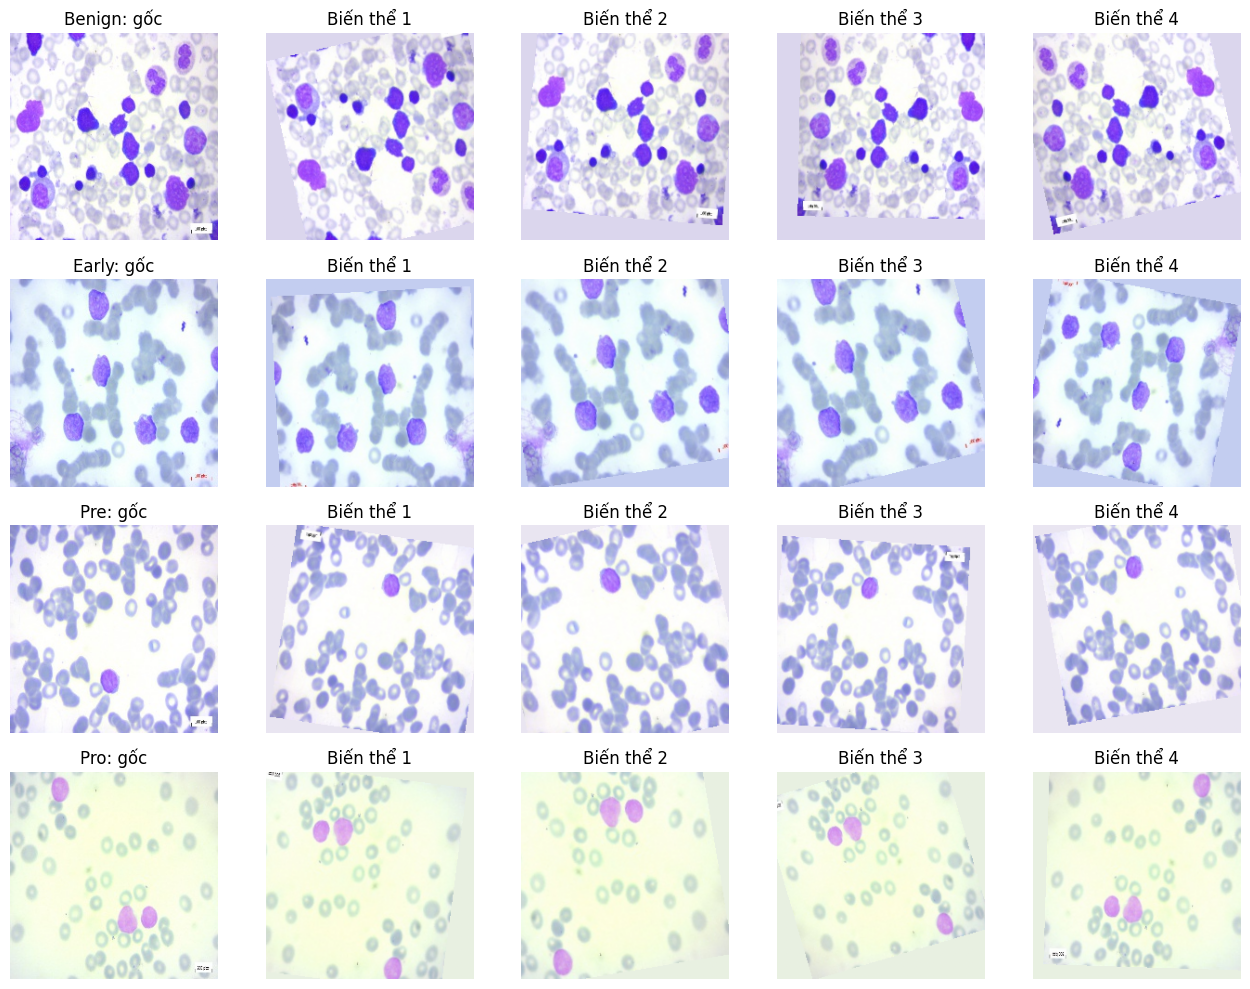

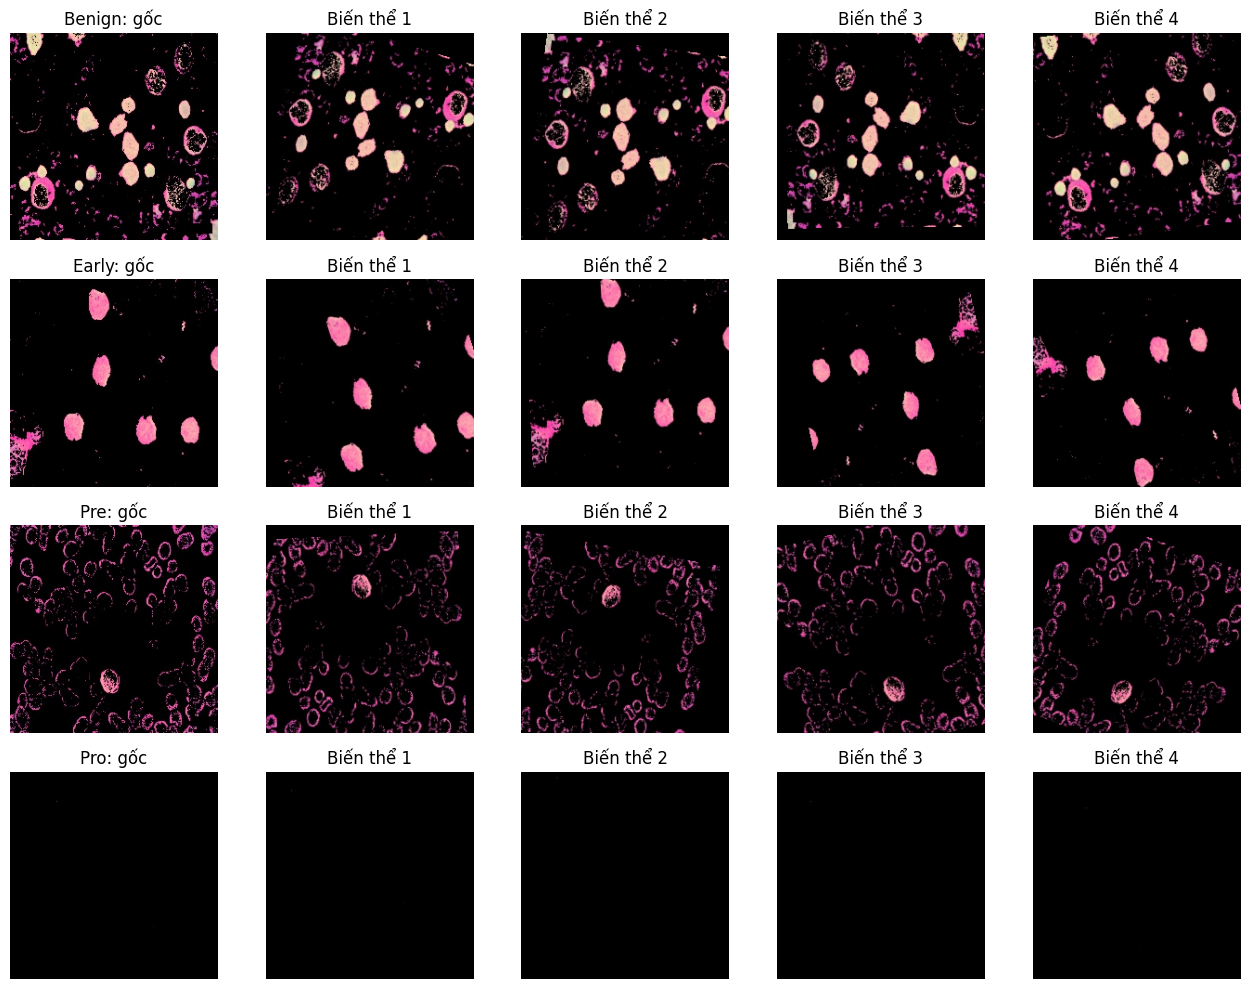

Sẵn sàng: resnet_loaders, mobile_loaders, efficient_loaders, cnn_loaders.


In [ ]:
for view in VIEWS:
    fig, axes = plt.subplots(len(CLASSES), 5, figsize=(13, 10))
    for i, cls in enumerate(CLASSES):
        row = manifest[(manifest['view']==view) & (manifest['split']=='train') & (manifest['label']==cls)].iloc[0]
        with Image.open(DATA_ROOT/row.relative_path) as image:
            original = image.convert('RGB')
        axes[i, 0].imshow(original)
        axes[i, 0].set_title(f'{cls}: gốc')
        ds = mobile_loaders[f'train_{view}'].dataset
        transform = ds.transform
        for j in range(1, 5):
            tensor = transform(original, view)
            rgb = (tensor*torch.tensor(transform.std)[:, None, None]
                   + torch.tensor(transform.mean)[:, None, None]).clamp(0, 1)
            axes[i, j].imshow(rgb.permute(1, 2, 0))
            axes[i, j].set_title(f'Biến thể {j}')
    for ax in axes.flat:
        ax.axis('off')
    plt.tight_layout()
    plt.savefig(PIPELINE_DIR/f'augmentation_{view}.png', dpi=150, bbox_inches='tight')
    plt.show()

# Đặt lại RNG sau phần minh họa trước khi chuyển sang huấn luyện.
reset_seed()
print('Sẵn sàng: resnet_loaders, mobile_loaders, efficient_loaders, cnn_loaders.')

## 8. Bắt đầu huấn luyện từ pipeline đã tạo
Các biến dưới đây sẵn có sau khi chạy notebook; ví dụ chọn Original cho ResNet50:
```python
train_loader = resnet_loaders['train_original']
val_loader = resnet_loaders['val_original']
test_loader = resnet_loaders['test_original']  # chỉ dùng khi đánh giá cuối
class_weights = resnet_weights['original']
# criterion = torch.nn.CrossEntropyLoss(weight=class_weights.to(device))
```
Dùng `mobile_loaders/mobile_weights`, `efficient_loaders/efficient_weights`, `cnn_loaders/cnn_weights` tương ứng. Đổi hậu tố sang `segmented` khi chạy view đó; mỗi thí nghiệm khởi tạo mô hình/optimizer mới.

CNN tự xây: tầng đầu nhận 3 kênh; tầng cuối trả 4 logits; không thêm softmax trước CrossEntropyLoss. Với ba backbone pretrained, thay classifier để trả 4 logits. Notebook này chỉ cung cấp dữ liệu, chưa tạo hoặc huấn luyện kiến trúc CNN riêng.

Dùng trong notebook khác (có `import torch`, `device` và model do bạn khai báo):
```python
import sys
sys.path.insert(0, '/content/drive/MyDrive/ALL_project/ALL_preprocessing_separate/auto_group_phash4_v1')
from all_data_pipeline import build_main_pipeline
loaders, weights = build_main_pipeline('mobilenet_v2')
# Tên khác: 'resnet50', 'efficientnet_b0', 'custom_cnn'
# Khi chuyển máy: build_main_pipeline('resnet50', data_root='/duong/dan/data-ALL')
```
Giữ cùng thư mục module, `main_pipeline_config.json`, `manifest_with_splits.csv`, `split_pairs.csv`; module mặc định tìm cấu hình cạnh file .py. Giữ nguyên ảnh nguồn sau khi tạo manifest. Giới hạn: kiểm tra metadata/fingerprint không thay thế quét lại pixel khi ảnh nguồn đã bị sửa.